# 04 · The spring 2020 COVID lockdown

**Question:** how much did air pollution in Milan change during the first COVID lockdown, compared with the same weeks in earlier years?

**Lockdown window:** 9 March – 3 May 2020. On 9 March Italy's restrictions (already in force in Lombardy from 8 March) were extended nationwide; from 4 May "Phase 2" began to reopen activity. We compare these dates with **the same calendar dates** in other years, because pollution depends strongly on the season (notebook 03).

**The hard part is the comparison.** Air pollution varies a lot from year to year because of weather, and it has been falling every year anyway. A naive "2020 vs the average of earlier years" mixes up three things: the lockdown, the long-term decline, and that spring's weather. So we use three comparisons, each one stricter than the last:

1. **Naive:** 2020 vs the 2015–2019 average for the same weeks.
2. **Trend-adjusted:** 2020 vs what the 2015–2019 trend line predicts for 2020.
3. **Ratio to the same year's winter (a difference-in-differences idea):** divide each year's lockdown-window mean by its own 1 Jan – 20 Feb mean (before COVID restrictions). This removes anything that makes a whole year cleaner or dirtier, such as the long-term trend. Then we check whether 2020's ratio is unusual compared with *every* other year: a **placebo test**.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import DATA_PROCESSED, POLLUTANTS, UNIT
from src.analysis import window_table, pct_change
from src.plotting import set_style, add_source, save, COLORS, GREY, LIGHT_GREY
set_style()

city = pd.read_parquet(DATA_PROCESSED / "daily_city.parquet")
station = pd.read_parquet(DATA_PROCESSED / "daily_station.parquet")
LOCK = ("03-09", "05-03")   # lockdown window
PRE = ("01-01", "02-20")    # before any COVID restriction in Lombardy (first local cases: 21 Feb)
YEARS = list(range(2015, 2026))
BASE = list(range(2015, 2020))

## Window means for every year

In [2]:
lock = window_table(city, YEARS, *LOCK)
pre = window_table(city, YEARS, *PRE)
pd.concat({"9 Mar – 3 May": lock, "1 Jan – 20 Feb": pre}, axis=1).round(1)

9 Mar – 3 May             1 Jan – 20 Feb            
              PM10 PM2.5   NO2           PM10 PM2.5   NO2
year                                                     
2015          36.3  28.4  58.7           57.7  47.7  80.7
2016          31.2  24.0  50.0           50.5  45.3  66.2
2017          37.4  26.0  48.8           65.6  51.3  70.9
2018          30.1  18.8  51.2           45.3  33.5  60.2
2019          24.3  16.9  41.2           54.9  42.2  66.0
2020          27.6  18.2  28.4           62.5  48.0  68.6
2021          27.9  21.6  36.7           37.7  31.1  52.2
2022          33.8  25.2  41.9           55.1  40.1  56.9
2023          22.2  14.0  31.8           38.4  29.8  51.1
2024          22.4  14.1  29.3           53.5  41.1  53.0
2025          19.8  13.3  29.3           37.7  27.4  43.4

## Comparison 1 — naive: 2020 vs the 2015–2019 average

In [3]:
naive = pct_change(lock.loc[2020], lock.loc[BASE].mean())
naive_pre = pct_change(pre.loc[2020], pre.loc[BASE].mean())
pd.DataFrame({"lockdown window, % vs 2015–19": naive, "pre-lockdown window, % vs 2015–19": naive_pre}).round(1)

,"lockdown window, % vs 2015–19","pre-lockdown window, % vs 2015–19"
PM10,-13.3,14.1
PM2.5,-20.0,9.0
NO2,-43.1,-0.2


Before reading the lockdown column, look at the **pre-lockdown** column. In January–February 2020, before any restriction, NO2 was at its normal level and PM was even *higher* than usual. So 2020 was not simply a "clean year": something changed after early March.

## Comparison 2 — trend-adjusted

Pollution was already falling every year, so the 2015–2019 average overstates what 2020 "should" have been. We fit a straight line to the 2015–2019 window means and extend it to 2020.

In [4]:
def trend_expected(table, years, target=2020):
    return pd.Series({p: np.polyval(np.polyfit(years, table.loc[years, p], 1), target) for p in table.columns})

expected = trend_expected(lock, BASE)
trend_adj = pd.DataFrame({
    "expected 2020 (trend)": expected,
    "observed 2020": lock.loc[2020],
    "% vs expected": pct_change(lock.loc[2020], expected),
    "pre-window % vs expected": pct_change(pre.loc[2020], trend_expected(pre, BASE)),
})
trend_adj.round(1)

,expected 2020 (trend),observed 2020,% vs expected,pre-window % vs expected
PM10,24.3,27.6,13.5,21.4
PM2.5,14.3,18.2,27.3,29.2
NO2,39.8,28.4,-28.6,17.9


A trend line through only 5 noisy points is itself uncertain (especially for PM, where 2019 was unusually clean), so this number should be read as rough. The picture for NO2 is consistent: lower than expected even after removing the trend. For PM it is not.

## Comparison 3 — ratio to the same year's winter, with a placebo test

For every year: **ratio = (mean 9 Mar – 3 May) / (mean 1 Jan – 20 Feb)**. Spring is always cleaner than winter, so ratios are below 1. The question is whether 2020's spring was *more* cleaner than usual.

**Placebo test:** we compute the same "effect" for every year, comparing that year's ratio with the average ratio of all *other* non-2020 years. If 2020 is just one more ordinary year, its effect should look like the others.

In [5]:
ratio = lock / pre
others = [y for y in YEARS if y != 2020]
effect = pd.DataFrame({
    y: pct_change(ratio.loc[y], ratio.loc[[o for o in others if o != y]].mean()) for y in YEARS
}).T.rename_axis("year")
print("Ratio lockdown-window / winter-window:")
display(ratio.round(2).T)
print("'Effect' for each year (% vs the average ratio of the other non-2020 years):")
effect.round(1).T

Ratio lockdown-window / winter-window:


year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
PM10,0.63,0.62,0.57,0.67,0.44,0.44,0.74,0.61,0.58,0.42,0.52
PM2.5,0.59,0.53,0.51,0.56,0.40,0.38,0.70,0.63,0.47,0.34,0.49
NO2,0.73,0.76,0.69,0.85,0.62,0.41,0.70,0.74,0.62,0.55,0.68


'Effect' for each year (% vs the average ratio of the other non-2020 years):


year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
PM10,9.6,7.1,-2.0,16.6,-25.5,-23.9,31.7,6.4,-0.4,-29.9,-10.4
PM2.5,15.9,1.6,-2.9,8.4,-25.3,-27.1,38.7,23.2,-11.0,-36.4,-7.6
NO2,5.5,10.0,-0.7,25.8,-11.1,-40.3,1.4,6.7,-11.3,-22.0,-2.8


In [6]:
rank = effect.rank()  # 1 = most negative
summary = pd.DataFrame({
    "2020 effect %": effect.loc[2020],
    "most negative placebo year %": effect.loc[others].min(),
    "2020 rank (1 = lowest of 11)": rank.loc[2020].astype(int),
})
summary.round(1)

,2020 effect %,most negative placebo year %,2020 rank (1 = lowest of 11)
PM10,-23.9,-29.9,3
PM2.5,-27.1,-36.4,2
NO2,-40.3,-22.0,1


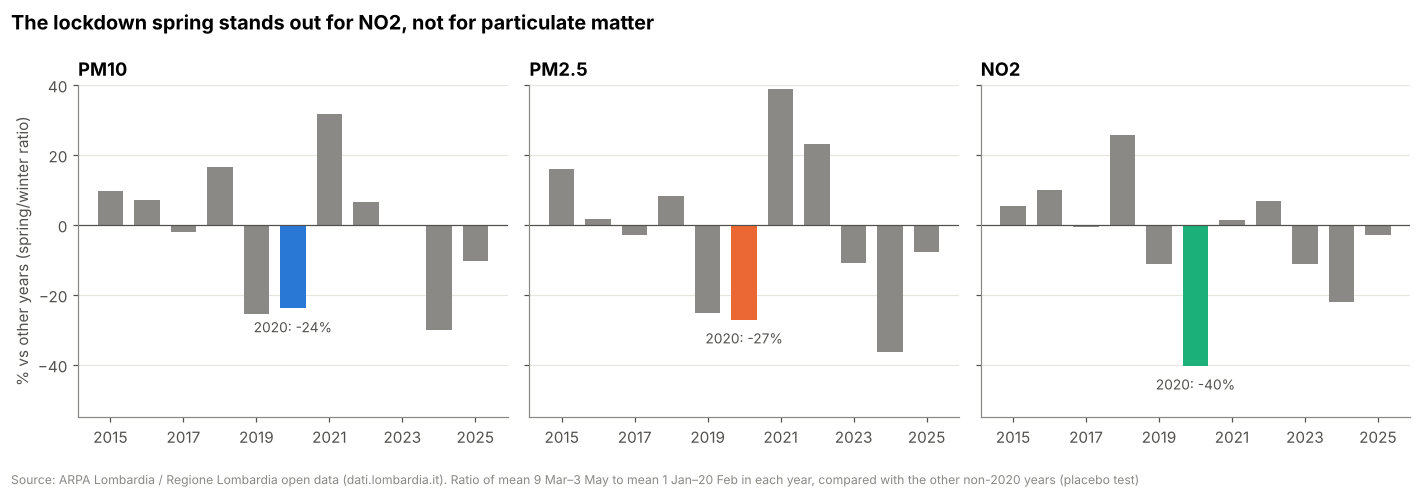

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, p in zip(axes, POLLUTANTS):
    colors = [COLORS[p] if y == 2020 else LIGHT_GREY for y in effect.index]
    ax.bar(effect.index, effect[p], color=colors, width=0.7)
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set_title(p, loc="left", fontsize=12)
    ax.set_xticks(YEARS[::2])
    v = effect.loc[2020, p]
    ax.text(2020, v - 3, f"2020: {v:.0f}%", ha="center", va="top", fontsize=9, color=GREY)
axes[0].set_ylabel("% vs other years (spring/winter ratio)")
axes[0].set_ylim(-55, 40)
fig.suptitle("The lockdown spring stands out for NO2, not for particulate matter",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
add_source(fig, "Ratio of mean 9 Mar–3 May to mean 1 Jan–20 Feb in each year, compared with the other non-2020 years (placebo test)")
save(fig, "06_lockdown_placebo")
plt.show()

## How the 2020 spring looked, week by week

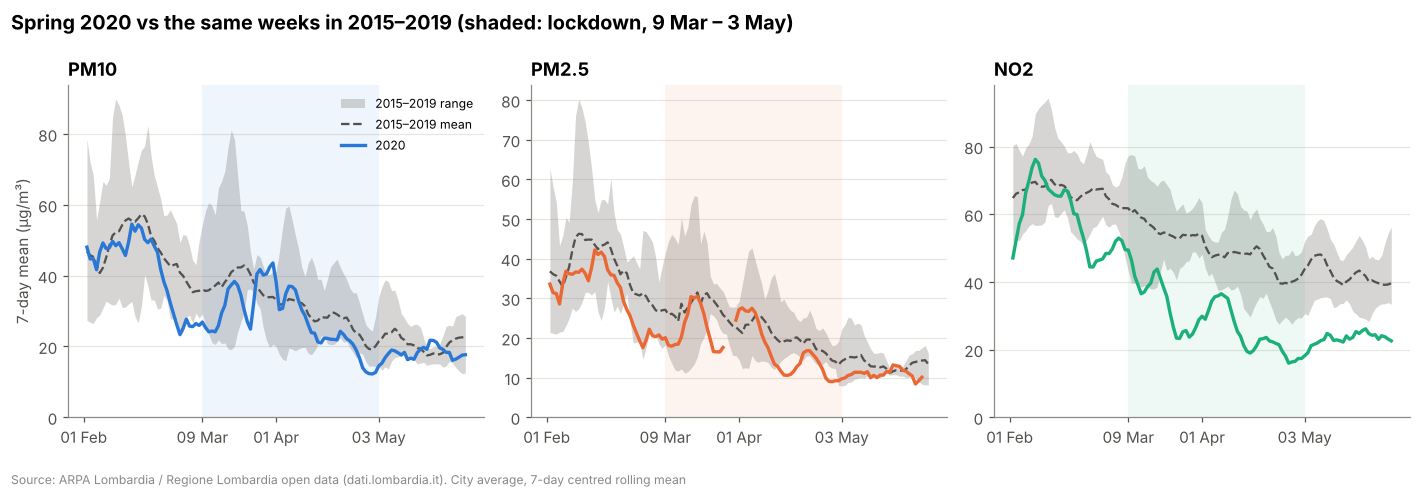

In [8]:
def weekly_window(series, year):
    s = series.loc[f"{year}-02-01":f"{year}-05-31"]
    s = s[~((s.index.month == 2) & (s.index.day == 29))]  # only leap years have 29 Feb: drop it everywhere
    s.index = s.index.map(lambda d: d.replace(year=2020))  # align calendars
    return s.rolling(7, center=True, min_periods=5).mean()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, p in zip(axes, POLLUTANTS):
    base = pd.concat({y: weekly_window(city[p], y) for y in BASE}, axis=1, sort=True)
    ax.fill_between(base.index, base.min(axis=1), base.max(axis=1), color=LIGHT_GREY, alpha=0.35, lw=0, label="2015–2019 range")
    ax.plot(base.index, base.mean(axis=1), color=GREY, lw=1.5, ls="--", label="2015–2019 mean")
    ax.plot(base.index, weekly_window(city[p], 2020), color=COLORS[p], lw=2.2, label="2020")
    ax.axvspan(pd.Timestamp("2020-03-09"), pd.Timestamp("2020-05-03"), color=COLORS[p], alpha=0.07, lw=0)
    ax.set_title(p, loc="left", fontsize=12)
    ax.set_ylim(0, None)
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d %b"))
    ax.set_xticks(pd.to_datetime(["2020-02-01", "2020-03-09", "2020-04-01", "2020-05-03"]))
axes[0].set_ylabel(f"7-day mean ({UNIT})")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Spring 2020 vs the same weeks in 2015–2019 (shaded: lockdown, 9 Mar – 3 May)",
             x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
add_source(fig, "City average, 7-day centred rolling mean")
save(fig, "07_lockdown_timeseries")
plt.show()

## Testing a hypothesis: did the rush-hour peak disappear?

**Hypothesis:** if the NO2 drop comes from less commuting traffic, the *morning rush-hour peak* should shrink the most. We compare weekday hourly profiles in the lockdown window with the same weeks in 2015–2019.

In [9]:
h = pd.read_parquet(DATA_PROCESSED / "hourly_no2.parquet")
md = h["hour_start"].dt.strftime("%m-%d")
in_win = (md >= LOCK[0]) & (md <= LOCK[1]) & (h["hour_start"].dt.day_of_week < 5)
hw = h[in_win]
yr = hw["hour_start"].dt.year
hod = hw["hour_start"].dt.hour
prof = pd.DataFrame({
    "2015–2019": hw[yr.isin(BASE)].groupby(hod[yr.isin(BASE)])["valore"].mean(),
    "2020": hw[yr == 2020].groupby(hod[yr == 2020])["valore"].mean(),
})
prof["% change"] = pct_change(prof["2020"], prof["2015–2019"])
print("Morning peak 06–09h, % change:", round(pct_change(prof.loc[6:9, "2020"].mean(), prof.loc[6:9, "2015–2019"].mean()), 1))
print("Night 01–04h, % change:      ", round(pct_change(prof.loc[1:4, "2020"].mean(), prof.loc[1:4, "2015–2019"].mean()), 1))
print("Afternoon 14–18h, % change:  ", round(pct_change(prof.loc[14:18, "2020"].mean(), prof.loc[14:18, "2015–2019"].mean()), 1))
prof.round(1).T

Morning peak 06–09h, % change: -29.9
Night 01–04h, % change:       -27.1
Afternoon 14–18h, % change:   -56.6


hour_start,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
2015–2019,52.4,47.0,42.3,41.2,43.8,55.0,69.5,74.5,70.0,61.5,...,39.1,40.1,42.6,47.3,55.0,63.5,65.0,61.8,58.8,57.4
2020,35.4,33.7,31.1,30.4,31.9,40.4,52.9,55.6,48.3,36.2,...,17.0,17.4,18.7,20.5,23.7,30.5,35.8,37.6,36.3,35.9
% change,-32.6,-28.4,-26.6,-26.3,-27.2,-26.5,-23.8,-25.4,-31.1,-41.1,...,-56.7,-56.5,-56.1,-56.7,-56.8,-52.0,-44.9,-39.1,-38.2,-37.5


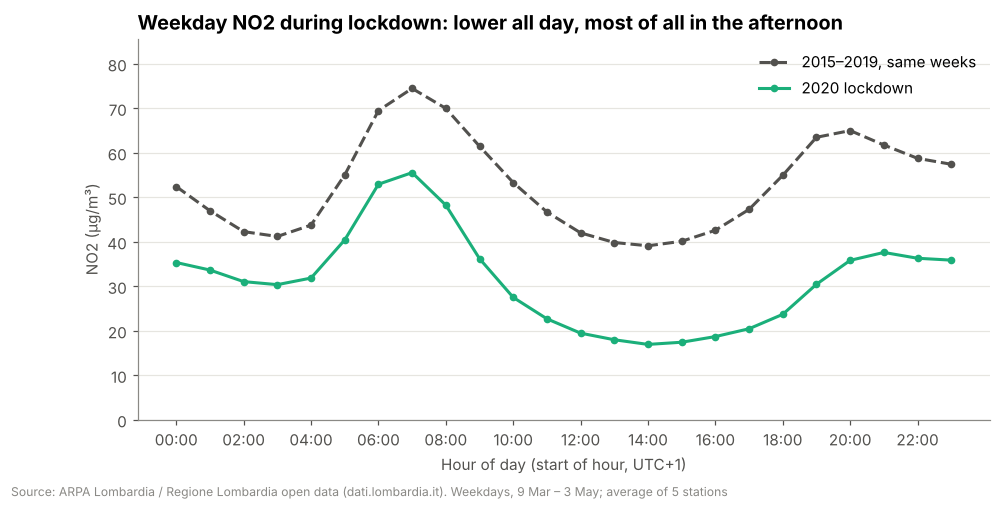

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(prof.index, prof["2015–2019"], color=GREY, ls="--", marker="o", ms=4, label="2015–2019, same weeks")
ax.plot(prof.index, prof["2020"], color=COLORS["NO2"], marker="o", ms=4, label="2020 lockdown")
ax.set_xticks(range(0, 24, 2), [f"{x:02d}:00" for x in range(0, 24, 2)])
ax.set_ylim(0, prof[["2015–2019", "2020"]].max().max() * 1.15)
ax.set_ylabel(f"NO2 ({UNIT})")
ax.set_xlabel("Hour of day (start of hour, UTC+1)")
ax.set_title("Weekday NO2 during lockdown: lower all day, most of all in the afternoon")
ax.legend(loc="upper right")
add_source(fig, "Weekdays, 9 Mar – 3 May; average of 5 stations")
save(fig, "08_lockdown_no2_hourly")
plt.show()

**Result: the hypothesis is only partly supported.** The morning peak is still there; it fell by about 30%, roughly as much as the night-time hours. The largest relative drop was in the **afternoon and early evening (about −56% between 14:00 and 18:00)**.

A plausible reading, which this data alone cannot confirm: essential early-morning trips (workers, deliveries) continued, while the spread-out daytime and evening activity (shopping, leisure, errands, the gradual return commute) largely stopped. In the afternoon the atmosphere is also best mixed, so concentrations reflect the whole day's city-wide emissions rather than the latest local burst. It is a good example of why you check a mechanism instead of assuming it.

## Station by station (NO2)

In [11]:
no2 = station[station["pollutant"] == "NO2"].pivot_table(index="date", columns="station", values="valore")
st_lock = window_table(no2, YEARS, *LOCK)
st_pre = window_table(no2, YEARS, *PRE)
st_ratio = st_lock / st_pre
st_effect = pct_change(st_ratio.loc[2020], st_ratio.loc[others].mean())
pd.DataFrame({"naive % vs 2015–19": pct_change(st_lock.loc[2020], st_lock.loc[BASE].mean()),
              "ratio method %": st_effect}).round(1).sort_values("ratio method %")

,naive % vs 2015–19,ratio method %
Milano v.Marche,-49.2,-48.0
Milano Verziere,-43.3,-43.9
Milano Pascal Città Studi,-46.1,-40.9
Milano v.Senato,-45.8,-37.9
Milano v.Liguria,-31.9,-36.8


## Interpretation and limitations

**What we can say:**
- NO2 during the lockdown was far below normal by every comparison: −43% vs the 2015–2019 average, about −29% vs the trend, and −40% with the ratio method, where 2020 is the most extreme of all 11 years (the next most extreme year is −22%). Every station shows a drop of 37–49%. NO2 was lower at every hour of the day, especially in the afternoon.
- PM10 and PM2.5 were lower than the 2015–2019 average (−13% and −20%), but once the long-term trend and the year's own winter level are taken into account, 2020 is **not** unusual: 2019 and 2024, with no lockdown, had equally low or lower spring/winter ratios. This fits what is known about PM in the Po Valley: much of it is *secondary* (formed in the air from ammonia from agriculture, plus NOx and other gases) or comes from domestic heating, which increased while people stayed at home.

**What we cannot say:**
- **This is not a causal estimate in the strict sense.** We compare 2020 with other years; we do not observe the same spring without a lockdown. Weather in spring 2020 (wind, rain, mixing height) could have helped or hurt, and we have not included weather data. The placebo test shows that 2020's NO2 drop is larger than ordinary weather differences between years, which makes a lockdown effect very plausible, but it does not prove it.
- **The windows are an assumption.** Lockdown dates are clear-cut, but behaviour changed gradually from late February (schools closed in Lombardy from 24 February).
- **Station coverage:** 5 NO2 stations and only 2–3 PM stations, all in the city. Results describe these sites, not every street in Milan.
- A more rigorous next step would be a "de-weathering" model (e.g. gradient boosting on meteorological variables trained on 2015–2019, used to predict a "business-as-usual" 2020) using ARPA's weather sensor data.